other references:
- MIT courseware (also check videos and recitations in the link provied):Introduction to Algorithms, Lecture 9: Breadth-First Search : https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/mit6_006s20_lec9/

- check network models as explained in this book: *Operations Research APPLICATIONS AND ALGORITHMS FOURTH EDITION Wayne L. Winston INDIANA UNIVERSITY*


so if your moving from one state to another state , then its a graph problem???

An Adjacency List
<div style="display: flex; justify-content: space-around; align-items: center;">
    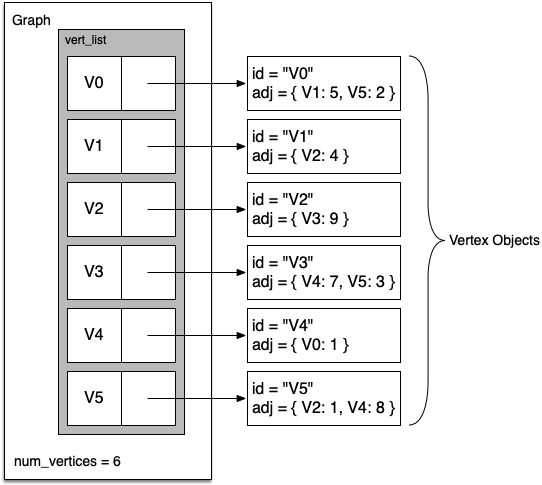
    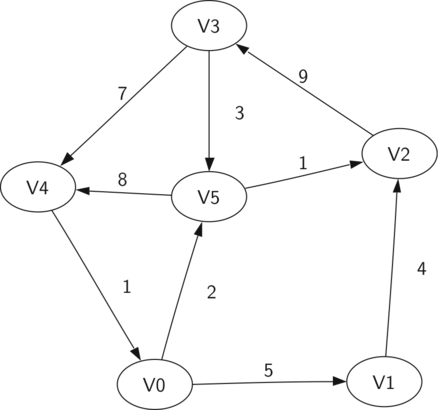
</div>


In [1]:
#code from AI

class Vertex:
    def __init__(self, key):
        """Initializes a vertex with a unique key and an empty neighbors dictionary."""
        self.id = key
        self.neighbors = {}  # Format: {connected_vertex_object: edge_weight}

    def set_neighbor(self, nbr, weight=0):
        """Adds a directed connection from this vertex to another vertex object with a weight."""
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        """Returns all vertex objects connected to this vertex."""
        return self.neighbors.keys()

    def get_key(self):
        """Returns the unique key identification of this vertex."""
        return self.id

    def get_neighbor(self, nbr):
        """Returns the edge weight linking this vertex to the target neighbor vertex."""
        return self.neighbors[nbr]

    def __repr__(self):
        """Custom string representation to match your sample layout format."""
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        """Initializes a master graph mapping containing a dictionary of vertices."""
        self.vertices = {}  # Maps: key -> Vertex object

    def set_vertex(self, key):
        """Creates a new Vertex instance if it does not exist and saves it in the master map."""
        if key not in self.vertices:
            new_vertex = Vertex(key)
            self.vertices[key] = new_vertex
        return self.vertices[key]

    def get_vertex(self, key):
        """Retrieves a specific Vertex object from the graph by its key name."""
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        """Connects two vertices together, creating them first if they do not exist."""
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
            
        # Set neighbor relationship between the actual Vertex objects
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)

    def get_vertices(self):
        """Returns the names/keys of all vertices present in the graph map."""
        return self.vertices.keys()

    def __iter__(self):
        """Enables looping directly over all Vertex objects in the master graph."""
        return iter(self.vertices.values())


# =====================================================================
# 🚀 Running Your Exact Sample Implementation Session Tasks
# =====================================================================

print("--- 🛠️ Initializing Graph & Vertices ---")
g = Graph()

# Create 6 vertices numbered 0 through 5
for i in range(6):
    g.set_vertex(i)

# Display vertices map layout
print("g.vertices structure:")
print(g.vertices)
print()

print("--- ⚡ Injecting Graph Weighted Edges ---")
g.add_edge(0, 1, 5)
g.add_edge(0, 5, 2)
g.add_edge(1, 2, 4)
g.add_edge(2, 3, 9)
g.add_edge(3, 4, 7)
g.add_edge(3, 5, 3)
g.add_edge(4, 0, 1)
g.add_edge(5, 4, 8)
g.add_edge(5, 2, 1)
print("All edges saved successfully.\n")

print("--- 🔍 Running Verification Iteration Loop ---")
for v in g:
    for w in v.get_neighbors():
        print(f"({v.get_key()}, {w.get_key()})")


--- 🛠️ Initializing Graph & Vertices ---
g.vertices structure:
{0: Vertex(0), 1: Vertex(1), 2: Vertex(2), 3: Vertex(3), 4: Vertex(4), 5: Vertex(5)}

--- ⚡ Injecting Graph Weighted Edges ---
All edges saved successfully.

--- 🔍 Running Verification Iteration Loop ---
(0, 1)
(0, 5)
(1, 2)
(2, 3)
(3, 4)
(3, 5)
(4, 0)
(5, 4)
(5, 2)


**Some other links**


- Breadth First Search Visually Explained | BFS | Graphs by ByteQuest: https://youtu.be/m1_0UlIFnLs?si=fXt0LHaEIK7DbIWU
- Breadth First Search (BFS): Visualized and Explained by Reducible: https://youtu.be/xlVX7dXLS64?si=xsMz6kr5r7sx0Vcq
- Breadth first search | BFS | Breadth first traversal by Techdose: https://youtu.be/YYq38LTz774?si=DnPPww3qnkODvqK1
- Word Ladder | Leetcode #127 by Techdose: https://youtu.be/ZVJ3asMoZ18?si=srA7SMI_GnuzxFNi
- Word Ladder 2 | Leetcode #126 | BFS + DFS by Techdose : https://youtu.be/mIZJIuMpI2M?si=-_PbAltOL9FnPQAr



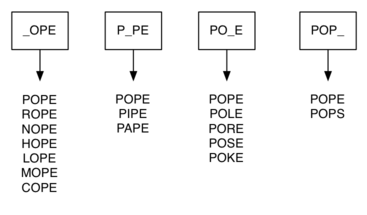

In Python, we can implement the scheme we have just described by using a dictionary. The labels on the buckets we have just described are the keys in our dictionary. The value stored for each key is a list of words. Once we have the dictionary built, we can create the graph. We start our graph by creating a vertex for each word in the graph. Then we create edges between all the vertices we find for words found under the same key in the dictionary

#### 🪜 Word Ladder Paths: Shortest Path Dynamics & Reconstruction Analysis

This notebook analyzes the mathematical and structural logic behind **Breadth-First Search (BFS)** shortest path guarantees, followed by a code syntax breakdown and time complexity profiling of the path reconstruction phase.

---

##### 🎯 1. How the Shortest Path is Achieved via BFS

The guarantee of discovering the absolute shortest path comes down to a core structural property of **Breadth-First Search (BFS)**: it explores graphs in strict **concentric levels** radiating outward from the starting vertex.

##### The Level-Order Guarantee
* **Level 0:** The algorithm starts at the root node (`FOOL`).
* **Level 1:** It sweeps and identifies all immediate neighbors exactly 1 step away (`POOL`, `FOIL`, `FOUL`, `COOL`). These are flagged with a distance of `1`.
* **Level 2:** Only after **all** Level 1 nodes are completely processed does the queue release them to uncover grandchildren exactly 2 steps away (`POLL`, `FAIL`).

##### Why an Invalidation is Impossible
Because BFS relies strictly on a First-In, First-Out (**Queue**), nodes are processed sequentially in order of increasing distance. 

If a destination word (like `SAGE`) is discovered on Level 4, it is mathematically impossible for a 2-step or 3-step pathway to exist elsewhere in the graph. If a shorter route existed, the level-order sweep would have run into it during an earlier iteration loop.

Once a node is discovered, its state color shifts from `white` to `gray`, and the code explicitly blocks any future path from overwriting it:
```python
if neighbor.color == "white":
```
This ensures that the **very first time** BFS hits a node, it locks in the absolute shortest path distance and permanently attaches its most direct parent pointer (`previous`).

---

##### 🛠️ 2. Syntax Breakdown: Reconstructing the Path

When BFS terminates, the target node (`SAGE`) only knows its immediate parent (`PALE`). `PALE` only knows its parent (`POLL`), and so on, back to `FOOL`. To output this path in proper chronological order (start-to-finish), the code climbs **backward** through that pointer chain and systematically reverses the sequence.

##### Code Segment Analysis

```python
# Climb up the predecessor chain until reaching the root (None)
while current is not None:
    path.insert(0, current.get_key())
    current = current.previous
    
print(" -> ".join(path))
```

* **`while current is not None:`**
  Starts at the destination node and loops continuously, jumping from child to parent. Because the initial starting node (`FOOL`) had its `.previous` pointer initialized to `None`, hitting `None` flags that the algorithm has successfully climbed to the top of the tree and breaks the loop.
* **`path.insert(0, current.get_key())`**
  The `.insert(0, item)` function forces each new word into the **very front (index 0)** of the array, shifting existing items to the right. Since we are traversing backward, inserting at the front actively reverses the order, resulting in a clean chronological timeline sequence:
  1. `['SAGE']`
  2. `['PALE', 'SAGE']`
  3. `['POLL', 'PALE', 'SAGE']` ... and so on.
* **`current = current.previous`**
  This reassigns the tracking variable to point to the immediate parent node, moving the cursor up one link in the tree branch chain to prepare for the next loop pass.
* **`" -> ".join(path)`**
  Stitches the finalized list of word strings together into a single flat string, anchoring the `" -> "` characters cleanly between elements:
  `FOOL -> POOL -> POLL -> PALE -> SAGE`

---

##### 📊 3. Time Complexity Scaling of Path Reconstruction

How does this reconstruction loop scale when the length of the word chain grows? Let's evaluate the asymptotic math.

If a word ladder chain has a total length of \(K\) words (meaning there are \(K\) steps from the start word to the target word):

1. **The Loop Transitions:** The `while` loop runs exactly \(K\) times because it must visit each vertex in the path once to get back to the root.
2. **The Hidden Cost of Insertion:** In Python, standard lists are implemented internally as dynamic arrays. When you call `path.insert(0, item)`, Python cannot just put the item at the front in constant time. It must physically slide every single existing element in the array one slot to the right in memory.
   * The 1st insertion takes \(1\) step.
   * The 2nd insertion takes \(2\) steps.
   * The \(K\)-th insertion takes \(K\) steps.

##### 📐 The Mathematical Proof
Summing these operations up results in an arithmetic series computation:
\[\text{Total Shifts} = 1 + 2 + 3 + \dots + K = \frac{K(K + 1)}{2} = \mathcal{O}(K^2)\]

Thus, the path reconstruction loop scales **quadratically** (\(\mathcal{O}(K^2)\)) relative to the length of the word chain, not linearly!

##### 💡 High-Performance Optimization
For very long paths, you can optimize this down to strict linear time (\(\mathcal{O}(K)\)) by simply using `.append()` to push items to the *end* of the list (which costs constant \(\mathcal{O}(1)\) time), and then reversing the entire list at the very end before printing:

```python
# Optimal O(K) Linear Time Reconstruction
while current is not None:
    path.append(current.get_key())  # O(1) operation
    current = current.previous

path.reverse()  # O(K) operation at the very end
print(" -> ".join(path))
```


In [2]:
# =====================================================================
# 1. GRAPH FOUNDATION CLASSES (Vertex and Graph)
# =====================================================================

class Vertex:
    def __init__(self, key):
        """Initializes a vertex representing a single word."""
        self.id = key
        self.neighbors = {}  # Format: {connected_vertex_object: weight}

    def set_neighbor(self, nbr, weight=0):
        """Adds a directed connection to another vertex object."""
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        """Returns all vertex objects connected to this vertex."""
        return self.neighbors.keys()

    def get_key(self):
        """Returns the word key of this vertex."""
        return self.id

    def __repr__(self):
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        """Master graph dictionary tracking all word vertices."""
        self.vertices = {}  # Format: {word_string: Vertex_object}

    def set_vertex(self, key):
        """Registers a word string as a new Vertex object if absent."""
        if key not in self.vertices:
            new_vertex = Vertex(key)
            self.vertices[key] = new_vertex
        return self.vertices[key]

    def get_vertex(self, key):
        """Retrieves a specific Vertex object by its word name."""
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        """Creates a bidirectional edge linking two words together."""
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        # Word ladders are undirected graphs, so connect them both ways
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)
        self.vertices[to_key].set_neighbor(self.vertices[from_key], weight)

    def __iter__(self):
        """Enables clean loops over all active Vertex objects."""
        return iter(self.vertices.values())


# =====================================================================
# 2. CORE IMPLEMENTATION: THE BUCKETS AND GRAPH BUILD ENGINE
# =====================================================================

def build_graph(word_file_list):
    """
    Builds a word connection graph using a wildcard bucket dictionary.
    Time Complexity: O(N * Word_Length) which is effectively linear O(N).
    """
    buckets = {}
    g = Graph()

    # Phase 1: Group words into wildcard buckets
    for word in word_file_list:
        # Create wildcards by replacing each letter position with an underscore
        for i in range(len(word)):
            bucket_label = word[:i] + "_" + word[i+1:]
            
            # Install the bucket key array if new, then append the word
            if bucket_label not in buckets:
                buckets[bucket_label] = []
            buckets[bucket_label].append(word)

    # Phase 2: Add vertices and construct edges between words in the same bucket
    for bucket_label in buckets.keys():
        word_list = buckets[bucket_label]
        
        # Compare all pairs of words grouped inside this specific bucket
        for word1 in word_list:
            for word2 in word_list:
                if word1 != word2:
                    # Connects word1 and word2 with an edge in the master graph framework
                    g.add_edge(word1, word2)
                    
    return g, buckets


# =====================================================================
# 3. VERIFICATION EXECUTION RUNTIME
# =====================================================================

# Sample list of 4-letter words containing variations
sample_words = ["POPE", "POPS", "COPE", "PALE", "SALE", "PAGE"]

print("📥 Initial Word Pool Processing:", sample_words)

# Generate graph and check internal buckets layout
word_graph, wildcard_buckets = build_graph(sample_words)

print("\n📦 Visualizing Populated Wildcard Buckets Mapping:")
print("-" * 60)
for label, words in wildcard_buckets.items():
    # Only show buckets that successfully clustered more than one word for readability
    if len(words) > 1:
        print(f" Bucket '{label}' -> Contains: {words}")
print("-" * 60)

print("\n⚡ Verifying Graph Edges Construction via Iteration:")
print("-" * 60)
# Track connections to avoid printing duplicate undirected directions twice
printed_edges = set()

for vertex in word_graph:
    for neighbor in vertex.get_neighbors():
        edge_pair = tuple(sorted([vertex.get_key(), neighbor.get_key()]))
        if edge_pair not in printed_edges:
            print(f" Connected: [{edge_pair[0]}] ↔️  [{edge_pair[1]}]")
            """
            In Python, standard lists [] are mutable, which means they cannot be added to a tracking set() 
            or used as keys in a dictionary. Turning the list into a tuple() freezes it in memory, making it
            hashable and completely safe to use for tracking duplicates.
            """
            printed_edges.add(edge_pair)
print("-" * 60)


📥 Initial Word Pool Processing: ['POPE', 'POPS', 'COPE', 'PALE', 'SALE', 'PAGE']

📦 Visualizing Populated Wildcard Buckets Mapping:
------------------------------------------------------------
 Bucket '_OPE' -> Contains: ['POPE', 'COPE']
 Bucket 'POP_' -> Contains: ['POPE', 'POPS']
 Bucket '_ALE' -> Contains: ['PALE', 'SALE']
 Bucket 'PA_E' -> Contains: ['PALE', 'PAGE']
------------------------------------------------------------

⚡ Verifying Graph Edges Construction via Iteration:
------------------------------------------------------------
 Connected: [COPE] ↔️  [POPE]
 Connected: [POPE] ↔️  [POPS]
 Connected: [PALE] ↔️  [SALE]
 Connected: [PAGE] ↔️  [PALE]
------------------------------------------------------------


### breadth-first search (BFS)

In [25]:
#codeblock form AI
from collections import deque

# =====================================================================
# 1. OPTIMIZED QUEUE ADT (Using collections.deque for O(1) Operations)
# =====================================================================
class Queue:
    def __init__(self):
        # Using deque guarantees O(1) performance for both ends
        self.items = deque()

    def is_empty(self):
        return len(self.items) == 0

    def enqueue(self, item):
        # Appends directly to the right side in O(1) time
        self.items.append(item)

    def dequeue(self):
        # Pops directly from the left side (front) in O(1) time
        return self.items.popleft()

    def size(self):
        
        return len(self.items)

    def head(self):
        # Returns the first 5 elements as a list for previewing
        return list(self.items)[:5]


# =====================================================================
# 2. EXPANDED VERTEX & GRAPH CLASSES (With BFS State Attributes)
# =====================================================================
class Vertex:
    def __init__(self, key):
        self.id = key
        self.neighbors = {}
        
        # New BFS state tracking attributes
        self.color = "white"      # white = undiscovered, gray = discovering, black = explored
        self.distance = 0         # Distance from start node
        self.previous = None      # Predecessor link to trace the shortest path

    def set_neighbor(self, nbr, weight=0):
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        return self.neighbors.keys()

    def get_key(self):
        return self.id


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key) #creat an instance of a vertex
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        # Word ladders are undirected graphs
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)
        self.vertices[to_key].set_neighbor(self.vertices[from_key], weight)


# =====================================================================
# 3. WORD LADDER BUCKET SCHEME ENGINE
# =====================================================================
def build_word_graph(word_list):
    buckets = {}
    g = Graph()
    
    for word in word_list:
        for i in range(len(word)):
            bucket_label = word[:i] + "_" + word[i+1:]
            if bucket_label not in buckets:
                buckets[bucket_label] = []
            buckets[bucket_label].append(word)

    for bucket_label in buckets:
        associated_words = buckets[bucket_label]
        for word1 in associated_words:
            for word2 in associated_words:
                if word1 != word2:
                    g.add_edge(word1, word2)
    return g


# =====================================================================
# 4. BREADTH-FIRST SEARCH (BFS) & LADDER PRINTER
# =====================================================================
def bfs(start_vertex):
    """
    Performs a Breadth-First Search exploration across the graph nodes.
    Discovers all nodes level-by-level to calculate shortest pathways.
    """
    # Initialize start node values
    start_vertex.color = "gray"
    start_vertex.distance = 0
    start_vertex.previous = None
    
    vert_queue = Queue()
    vert_queue.enqueue(start_vertex)
    """
    the while loop is executed, at most, one time for each vertex in the graph (up to |𝑉| iterations).
    """
    
    while not vert_queue.is_empty():
        current_vert = vert_queue.dequeue()
        
        # Systematically explore each neighbor in the current node's adjacency list
        """
        The for loop, which is nested inside the while, is executed at most once for each edge in the graph
        (up to |𝐸| iterations).
        """
        for neighbor in current_vert.get_neighbors():
            if neighbor.color == "white":
                # Four steps for an undiscovered node:
                neighbor.color = "gray"
                neighbor.previous = current_vert
                neighbor.distance = current_vert.distance + 1
                vert_queue.enqueue(neighbor)
                
        # Completely finished scanning all immediate attachments
        current_vert.color = "black"


def print_word_ladder(end_vertex):
    """
    Traces the predecessor arrows backward from the end node to the root 
    to reconstruct and display the clean word ladder path sequence.
    """
    current = end_vertex
    path = []
    
    # Climb up the predecessor chain until reaching the root (None)
    while current is not None:
        path.insert(0, current.get_key())
        current = current.previous
        
    print(" -> ".join(path))


# =====================================================================
# 5. TEST VERIFICATION RUNTIME
# =====================================================================

# List of words building out the path from FOOL to SAGE
words_pool = [
    "FOOL", "POOL", "FOIL", "FOUL", "COOL", "POLL", "FAIL", "PALL", "SAGE", "PAGE"
]

# Connect extra bridging entries so SAGE is reachable from POLL or PALL
words_pool.extend(["SALE", "PALE", "POPE", "POPS"])

# 1. Build the graph layout
graph = build_word_graph(words_pool)

# 2. Trigger BFS exploration starting from the vertex 'FOOL'
start_node = graph.get_vertex("FOOL")
bfs(start_node)

print("=====================================================================")
print("🎯 WORD LADDER SOLVER SHORTEST PATHS RESULTS")
print("=====================================================================\n")

print("1. Path from FOOL back to FOOL (Distance 0):")
print_word_ladder(graph.get_vertex("FOOL"))
print()

print("2. Path from FOOL to COOL (Distance 1):")
print_word_ladder(graph.get_vertex("COOL"))
print()

print("3. Path from FOOL to POLL (Distance 2):")
print_word_ladder(graph.get_vertex("POLL"))
print()

print("4. Path from FOOL to SAGE (Final Word Problem Destination):")
target_node = graph.get_vertex("SAGE")
if target_node and target_node.color == "black":
    print_word_ladder(target_node)
    print(f"   Total Transformations Step Count: {target_node.distance}")
else:
    print("❌ No path found between the words.")


🎯 WORD LADDER SOLVER SHORTEST PATHS RESULTS

1. Path from FOOL back to FOOL (Distance 0):
FOOL

2. Path from FOOL to COOL (Distance 1):
FOOL -> COOL

3. Path from FOOL to POLL (Distance 2):
FOOL -> POOL -> POLL

4. Path from FOOL to SAGE (Final Word Problem Destination):
FOOL -> POOL -> POLL -> PALL -> PALE -> PAGE -> SAGE
   Total Transformations Step Count: 6


#### PLayground

In [4]:
# Completed implementation of a queue ADT
class Queue:
    def __init__(self):
        self.items = []
    def is_empty(self):
        return self.items == []
    def enqueue(self, item):
        self.items.insert(0,item) #this an O(n) operation , can we change the ends according to operation
    def dequeue(self):
        return self.items.pop()
    def size(self):
        return len(self.items)
    def head(self):
        return self. items[:5]

In [10]:
'abcd'[:3] + "_" + 'abcd'[3+1:]

'abc_'

In [22]:
nn = [2, 3, 5]
nn.extend([6, 7, 8])


# List of words building out the path from FOOL to SAGE
nnk = [
    "FOOL", "POOL", "FOIL", "FOUL", "COOL", "POLL", "FAIL", "PALL", "SAGE", "PAGE"
]

# Connect extra bridging entries so SAGE is reachable from POLL or PALL
nnk.extend(["SALE", "PALE", "POPE", "POPS"])

nnk

['FOOL',
 'POOL',
 'FOIL',
 'FOUL',
 'COOL',
 'POLL',
 'FAIL',
 'PALL',
 'SAGE',
 'PAGE',
 'SALE',
 'PALE',
 'POPE',
 'POPS']

In [21]:
nn

[2, 3, 5, 6, 7, 8]